# 02 – Baseline phân loại đa lớp
Stratified 80/20 + 5-Fold CV trên Train; thêm GroupShuffle theo Cluster ID. Gọi `src/train_baselines.py`.

In [ ]:
import sys, json, pandas as pd
sys.path.append('../src')
from IPython.display import Image, display
import train_baselines
train_baselines.main(fast=False)

E01  Multinomial Naive Bayes      Stratified 80/20   CV-F1=0.9616 Test Acc=0.9650 F1m=0.9663 (0.5s)
E02  Decision Tree                Stratified 80/20   CV-F1=0.9375 Test Acc=0.9398 F1m=0.9408 (1.8s)
E03  Logistic Regression          Stratified 80/20   CV-F1=0.9602 Test Acc=0.9642 F1m=0.9656 (5.4s)
E04  LinearSVC (SVM)              Stratified 80/20   CV-F1=0.9634 Test Acc=0.9669 F1m=0.9679 (1.1s)
E05  LinearSVC (SVM)              Stratified 80/20   CV-F1=0.9889 Test Acc=0.9922 F1m=0.9917 (4.4s)
E06  LinearSVC (SVM)              Stratified 80/20   CV-F1=0.9888 Test Acc=0.9925 F1m=0.9920 (10.3s)
E07  Decision Tree                Stratified 80/20   CV-F1=0.9309 Test Acc=0.9384 F1m=0.9359 (23.2s)
E08  HistGradientBoosting (thay X Stratified 80/20   CV-F1=0.9766 Test Acc=0.9796 F1m=0.9793 (70.1s)
E09  Random Forest                Stratified 80/20   CV-F1=0.9700 Test Acc=0.9738 F1m=0.9732 (71.8s)
E01-G Multinomial Naive Bayes      GroupShuffle 80/20 CV-F1=nan Test Acc=0.9407 F1m=0.9414 (0.8s

In [ ]:
pd.read_csv('../results/experiment_log_classification.csv')

,exp_id,date,task,model,features,params,split,n_train,n_test,cv_folds,cv_accuracy_mean,cv_f1_macro_mean,cv_f1_macro_std,cv_time_s,train_time_s,infer_ms_per_1k,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted,notes
0,E01,2026-11-07,Classification,Multinomial Naive Bayes,"Word TF-IDF (1,2)","{""alpha"": 0.1}",Stratified 80/20,28248,7063,5.0000,0.9602,0.9616,0.0014,2.6652,0.5104,15.4774,0.9650,0.9696,0.9636,0.9663,0.9651,Baseline tham chiếu (Proposal)
1,E02,2026-11-07,Classification,Decision Tree,"Word TF-IDF (1,2)","{""criterion"": ""gini"", ""max_depth"": null}",Stratified 80/20,28248,7063,5.0000,0.9374,0.9375,0.0023,7.7807,1.7798,14.5030,0.9398,0.9434,0.9388,0.9408,0.9398,Baseline cây đơn
2,E03,2026-11-07,Classification,Logistic Regression,"Word TF-IDF (1,2)","{""C"": 10, ""penalty"": ""l2"", ""solver"": ""lbfgs""}",Stratified 80/20,28248,7063,5.0000,0.9586,0.9602,0.0024,22.4421,5.3948,12.9945,0.9642,0.9682,0.9634,0.9656,0.9642,NaN
3,E04,2026-11-07,Classification,LinearSVC (SVM),"Word TF-IDF (1,2)","{""C"": 1.0, ""loss"": ""squared_hinge""}",Stratified 80/20,28248,7063,5.0000,0.9621,0.9634,0.0015,4.8277,1.0777,17.0765,0.9669,0.9685,0.9674,0.9679,0.9669,Baseline SVM
4,E05,2026-11-07,Classification,LinearSVC (SVM),Hybrid TF-IDF (word 1-2 + char_wb 3-5),"{""C"": 1.0}",Stratified 80/20,28248,7063,5.0000,0.9890,0.9889,0.0008,19.9585,4.3761,81.3908,0.9922,0.9920,0.9913,0.9917,0.9922,RQ1: thêm char n-grams
5,E06,2026-11-07,Classification,LinearSVC (SVM),Hybrid TF-IDF + Morph(5) + Merchant prior(10),"{""C"": 1.0}",Stratified 80/20,28248,7063,5.0000,0.9891,0.9888,0.0014,50.4789,10.2578,91.5897,0.9925,0.9923,0.9916,0.9920,0.9925,RQ1: thêm đặc trưng hình thái + merchant
6,E07,2026-11-07,Classification,Decision Tree,SVD-150 (Hybrid TF-IDF) + Morph + Merchant prior,"{""svd"": 150, ""min_samples_leaf"": 2}",Stratified 80/20,28248,7063,5.0000,0.9338,0.9309,0.0033,91.3546,23.2115,145.9175,0.9384,0.9356,0.9364,0.9359,0.9383,Cây trên không gian LSA
7,E08,2026-11-07,Classification,HistGradientBoosting (thay XGBoost),SVD-150 (Hybrid TF-IDF) + Morph + Merchant prior,"{""svd"": 150, ""max_iter"": 300, ""learning_rate"": 0.1, ""max_leaf_nodes"": 31}",Stratified 80/20,28248,7063,5.0000,0.9769,0.9766,0.0020,287.9099,70.0977,212.9884,0.9796,0.9801,0.9786,0.9793,0.9796,Gradient boosting (thay LightGBM/XGBoost)
8,E09,2026-11-07,Classification,Random Forest,SVD-150 (Hybrid TF-IDF) + Morph + Merchant prior,"{""svd"": 150, ""n_estimators"": 300}",Stratified 80/20,28248,7063,5.0000,0.9708,0.9700,0.0016,260.0887,71.7579,207.3675,0.9738,0.9750,0.9718,0.9732,0.9738,Ensemble bagging
9,E01-G,2026-11-07,Classification,Multinomial Naive Bayes,"Word TF-IDF (1,2)","{""alpha"": 0.1}",GroupShuffle 80/20,28157,7154,NaN,NaN,NaN,NaN,NaN,0.8099,22.3010,0.9407,0.9502,0.9351,0.9414,0.9408,Group split theo Cluster ID (kiểm tra rò rỉ cùng sản phẩm)


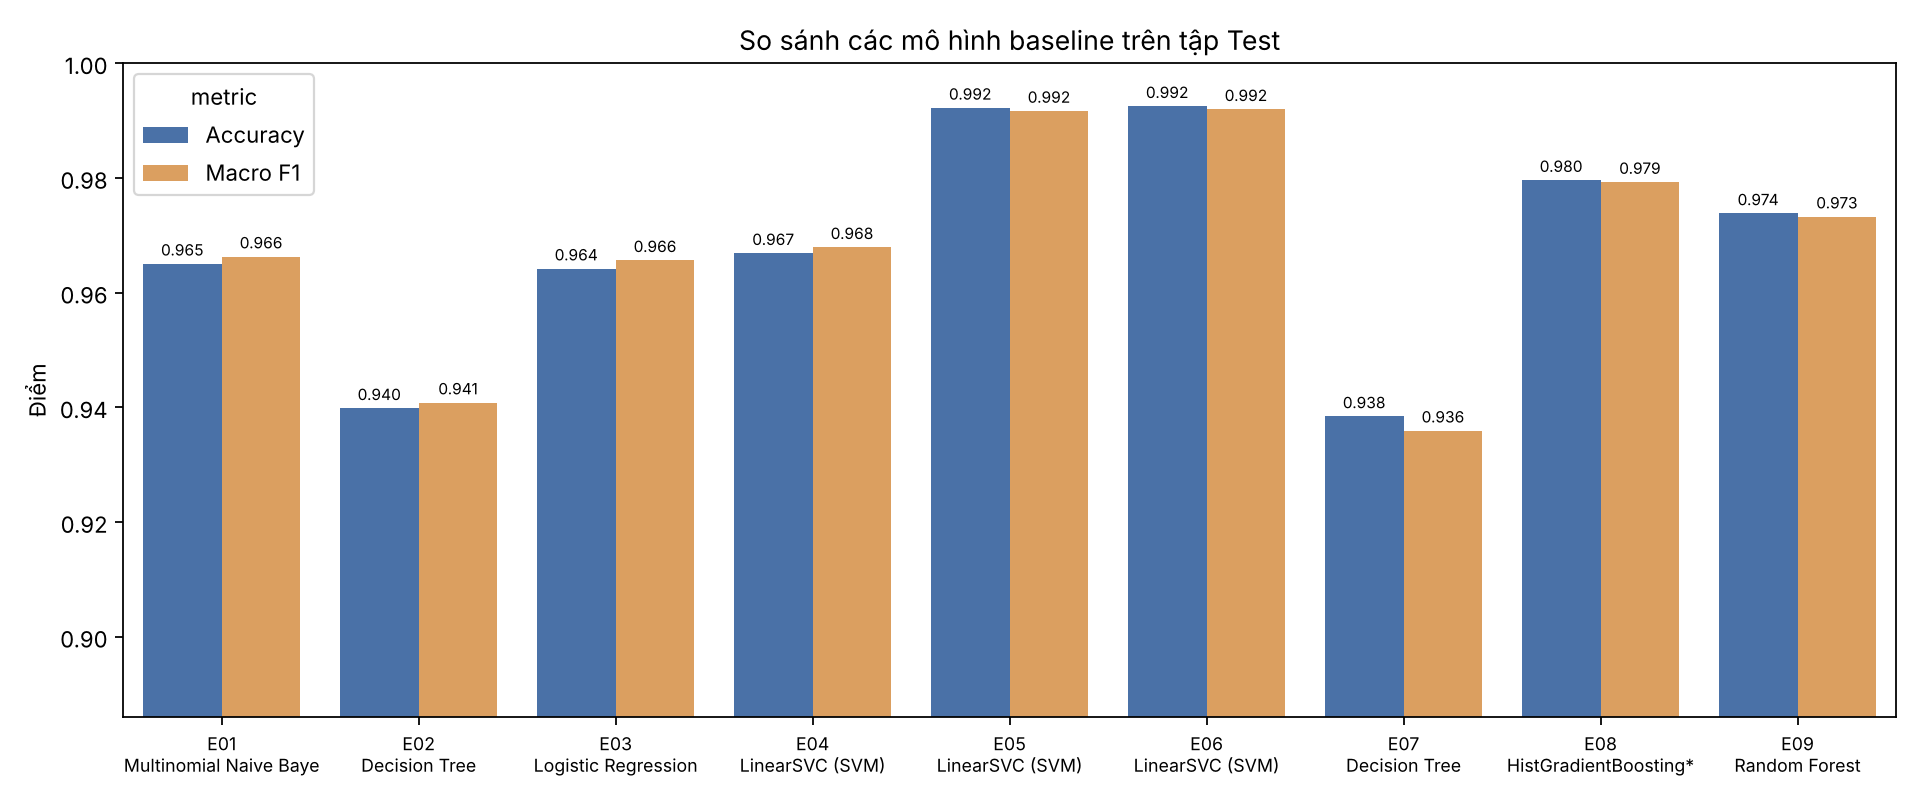

In [ ]:
display(Image('../figures/res_01_model_comparison.png'))

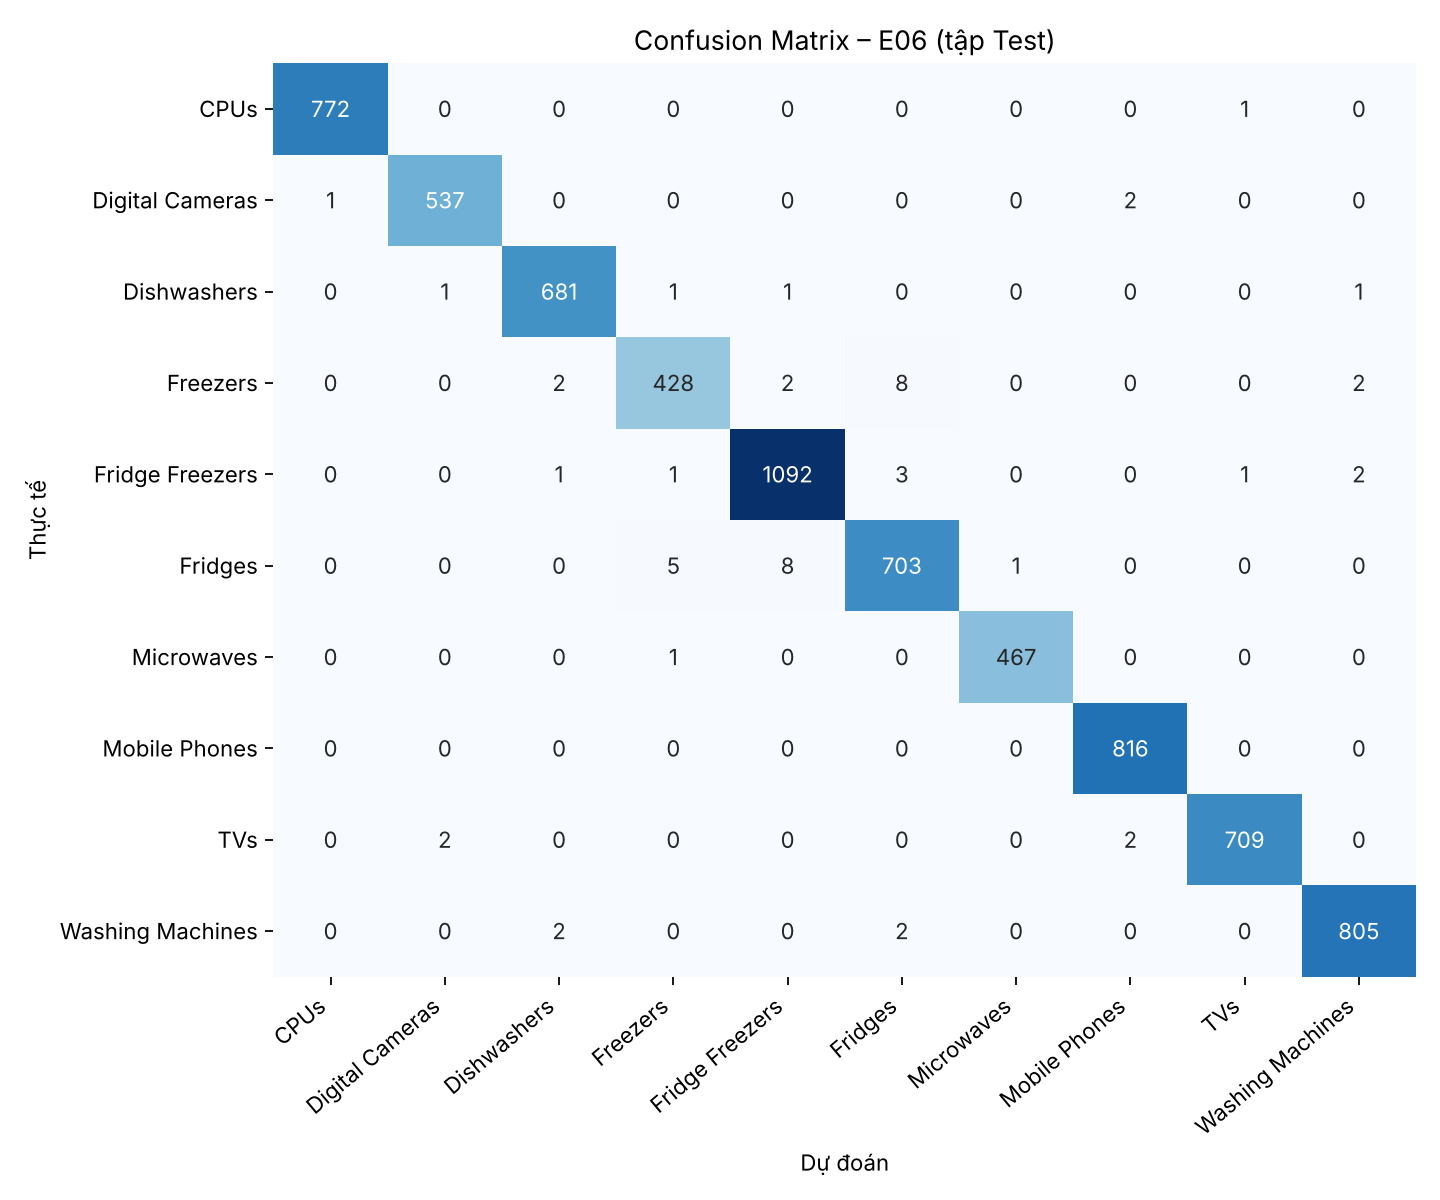

In [ ]:
display(Image('../figures/res_02_confusion_matrix_best.png'))

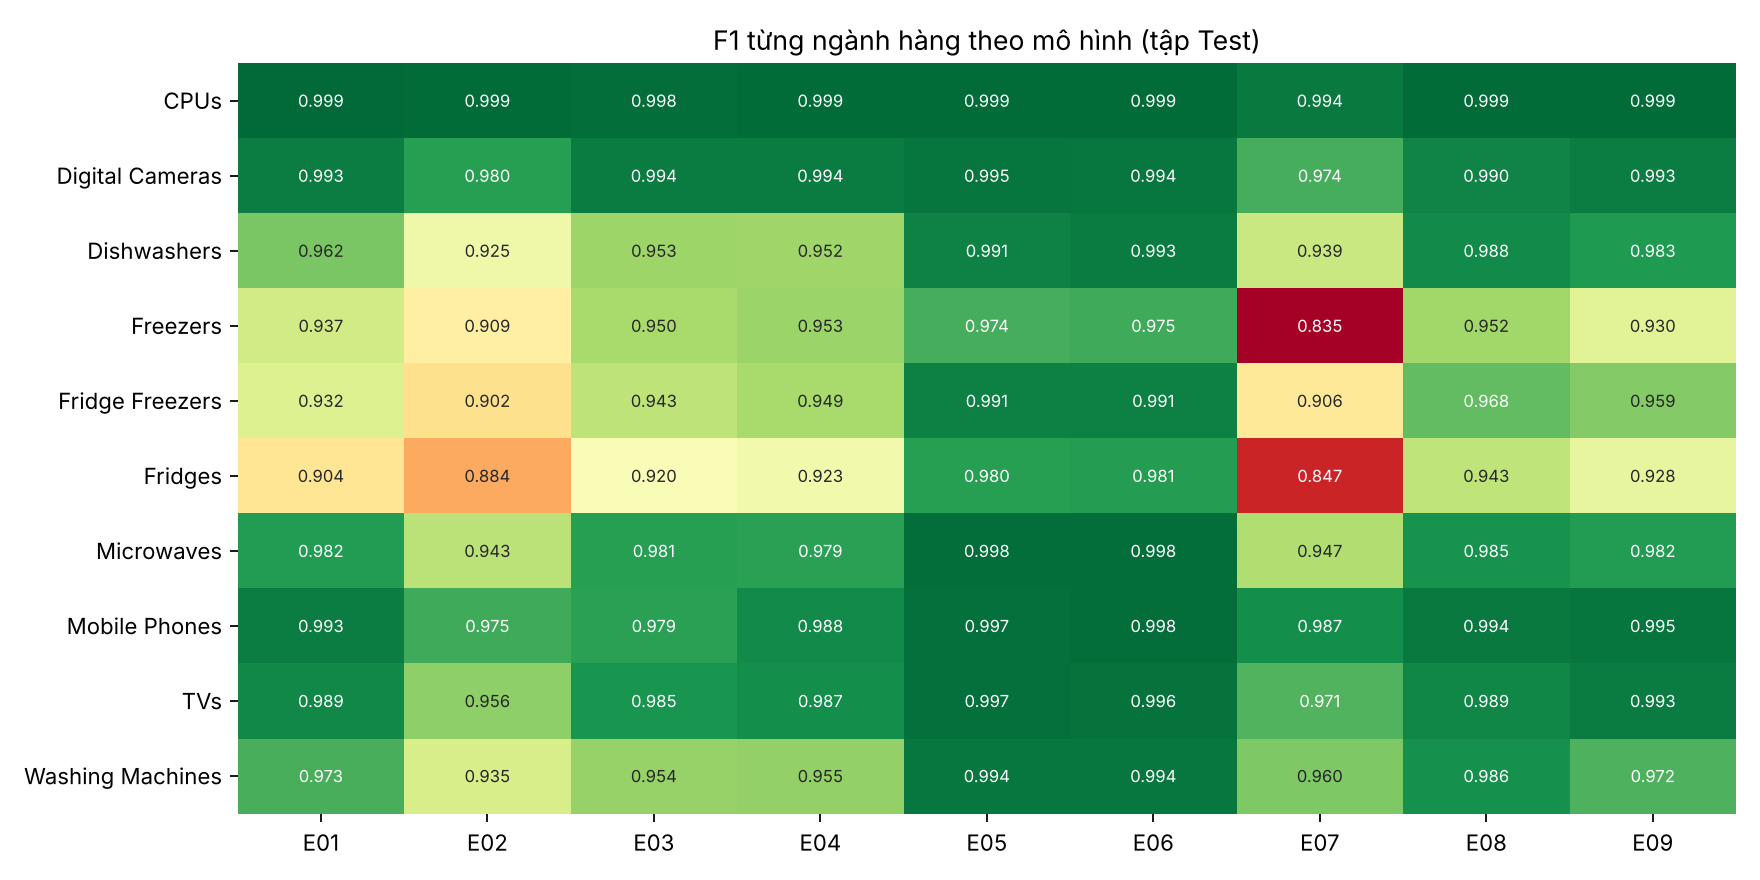

In [ ]:
display(Image('../figures/res_03_per_class_f1.png'))

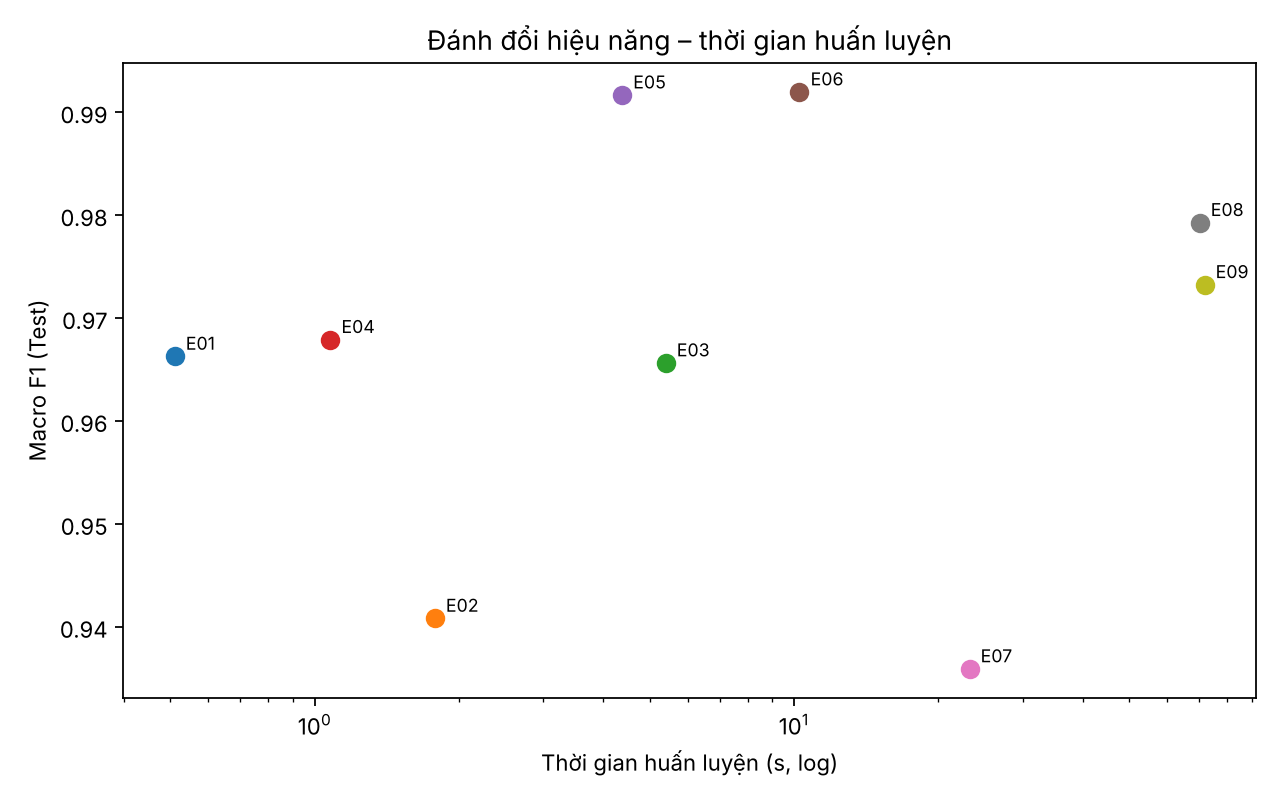

In [ ]:
display(Image('../figures/res_04_f1_vs_time.png'))

In [ ]:
pd.read_csv('../results/top_confusions_E06.csv')

,category_label,pred,count
0,Fridges,Fridge Freezers,8
1,Freezers,Fridges,8
2,Fridges,Freezers,5
3,Fridge Freezers,Fridges,3
4,Digital Cameras,Mobile Phones,2
5,Freezers,Dishwashers,2
6,TVs,Mobile Phones,2
7,Fridge Freezers,Washing Machines,2
8,Washing Machines,Dishwashers,2
9,Washing Machines,Fridges,2
